# Heart Disease Prediction — Part 1: The Basics

**Goal of this notebook:** take raw checkup data for 70,000 people and build models that predict
whether a person has **cardiovascular disease** (`cardio = 1`) or not (`cardio = 0`).

You will go through the full machine-learning workflow, one small step at a time:

| Step | What we do | Course link (CS582) |
|---|---|---|
| 1 | Load the data | Lab 0 (Python tools) |
| 2 | Look at the data | Lab 0 (statistics basics) |
| 3 | Clean impossible values | — |
| 4 | Create better features (age in years, BMI) | — |
| 5 | Explore with charts | — |
| 6 | Split into train / validation / test | Lecture 6 (validation) |
| 7 | Scale the features | Lecture 5 (inputs to an MLP) |
| 8 | Train an MLP neural network | Lectures 4–5 (MLP, backprop) |
| 9 | Evaluate with a confusion matrix | Lecture 6 (confusion matrix) |
| 10 | Compare with SVM, Random Forest, Naive Bayes | Lectures 8 and 15 |
| 11 | Choose a decision threshold that catches more sick patients | Lecture 6 |
| 12 | Use the model on a new patient + "what-if" | Lecture 11 (agents) |

---

### How to use a Jupyter notebook (if this is your first time)

- A notebook is made of **cells**. This box is a *text* (Markdown) cell. Grey boxes with code are *code* cells.
- Click a code cell and press **Shift + Enter** to run it. The result appears underneath.
- **Run cells in order, from top to bottom.** Later cells use variables created by earlier ones.
- If something gets confusing, use the menu **Kernel → Restart & Run All** (or **Run All** in VS Code) to start fresh.
- Lines that start with `#` inside code are **comments**: notes for humans, ignored by Python.

## Step 0 — Import the libraries

A **library** is a toolbox of code someone else wrote, so we don't have to write everything from scratch.

| Library | Nickname | What we use it for |
|---|---|---|
| pandas | `pd` | Tables of data (like Excel inside Python) |
| numpy | `np` | Fast math on numbers and arrays |
| matplotlib | `plt` | Drawing charts |
| seaborn | `sns` | Nicer statistical charts (built on matplotlib) |
| scikit-learn | `sklearn` | Machine-learning models, splitting, scaling, metrics |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine-learning tools from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

# A "random seed" makes random steps (like shuffling) give the SAME result every time
# you run the notebook. 42 is just a conventional choice — any number works.
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
print("Libraries loaded ✔")

Libraries loaded ✔


## Step 1 — Load the data

The file `data/cardio_train.csv` is a text file where each line is one patient.
Normally CSV means *comma*-separated, but this file uses **semicolons (`;`)**, so we must tell pandas `sep=";"`.

The result is a **DataFrame** — a table with rows (patients) and columns (measurements). We call it `df`.

In [2]:
df = pd.read_csv("data/cardio_train.csv", sep=";")

print("Shape (rows, columns):", df.shape)
df.head()   # show the first 5 rows

Shape (rows, columns): (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


**What the columns mean**

| Column | Meaning | Values |
|---|---|---|
| `id` | Patient ID number | not useful for prediction |
| `age` | Age **in days** | e.g. 18393 days ≈ 50 years |
| `gender` | Sex | 1 = woman, 2 = man |
| `height` | Height | cm |
| `weight` | Weight | kg |
| `ap_hi` | Systolic blood pressure (the top number) | mmHg, normal ≈ 120 |
| `ap_lo` | Diastolic blood pressure (the bottom number) | mmHg, normal ≈ 80 |
| `cholesterol` | Cholesterol level | 1 = normal, 2 = above normal, 3 = well above |
| `gluc` | Glucose (blood sugar) level | 1 = normal, 2 = above normal, 3 = well above |
| `smoke` | Smokes? | 0 = no, 1 = yes |
| `alco` | Drinks alcohol? | 0 = no, 1 = yes |
| `active` | Physically active? | 0 = no, 1 = yes |
| **`cardio`** | **Has cardiovascular disease? ← the TARGET** | 0 = no, 1 = yes |

Vocabulary you will see everywhere:
- **Features (X)** = the inputs the model looks at (everything except `cardio`).
- **Target (y)** = the answer we want to predict (`cardio`).

## Step 2 — Look at the data before touching it

Always inspect data first. Two quick checks:

1. `df.info()` — column types and whether any values are missing.
2. `df.describe()` — summary statistics: mean, min, max, etc. **Look at min and max: they reveal impossible values.**

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


Every column has 70,000 non-null values → **no missing values**.

In [4]:
df.describe().round(1)

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0,70000.0
mean,49972.4,19468.9,1.3,164.4,74.2,128.8,96.6,1.4,1.2,0.1,0.1,0.8,0.5
std,28851.3,2467.3,0.5,8.2,14.4,154.0,188.5,0.7,0.6,0.3,0.2,0.4,0.5
min,0.0,10798.0,1.0,55.0,10.0,-150.0,-70.0,1.0,1.0,0.0,0.0,0.0,0.0
25%,25006.8,17664.0,1.0,159.0,65.0,120.0,80.0,1.0,1.0,0.0,0.0,1.0,0.0
50%,50001.5,19703.0,1.0,165.0,72.0,120.0,80.0,1.0,1.0,0.0,0.0,1.0,0.0
75%,74889.2,21327.0,2.0,170.0,82.0,140.0,90.0,2.0,1.0,0.0,0.0,1.0,1.0
max,99999.0,23713.0,2.0,250.0,200.0,16020.0,11000.0,3.0,3.0,1.0,1.0,1.0,1.0


**Read the min / max rows carefully — this is where you catch problems:**

- `ap_hi` (top blood pressure) has a **min below 0** and a **max of 16020** — impossible. Real values are roughly 80–250.
- `ap_lo` has a **max of 11000** — also impossible (probably typos like 1100 for 110).
- `height` goes as low as 55 cm and `weight` as low as 10 kg for adults — almost certainly errors.

We fix these in Step 3. First, check the **target balance**: how many sick vs. healthy patients?

cardio
0    35021
1    34979
Name: count, dtype: int64

Percentage:
 cardio
0    50.0
1    50.0
Name: proportion, dtype: float64


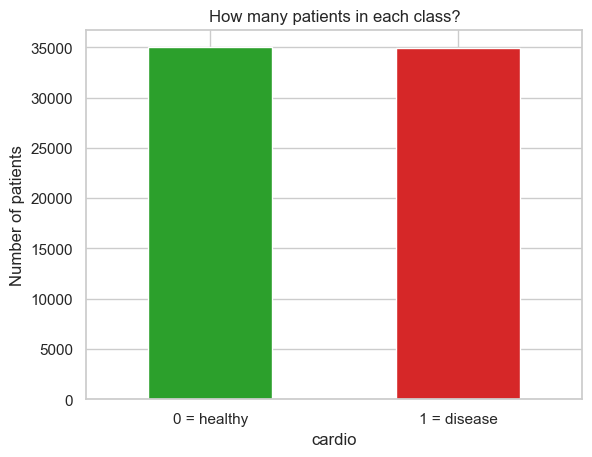

In [5]:
counts = df["cardio"].value_counts()
print(counts)
print("\nPercentage:\n", (df["cardio"].value_counts(normalize=True) * 100).round(1))

counts.plot(kind="bar", color=["tab:green", "tab:red"])
plt.xticks([0, 1], ["0 = healthy", "1 = disease"], rotation=0)
plt.title("How many patients in each class?")
plt.ylabel("Number of patients")
plt.show()

The classes are **balanced** (about 50% / 50%). That's good news:
- A model can't "cheat" by always guessing the majority class.
- **Accuracy is a fair first metric** here (Lecture 6 warns that accuracy is misleading when classes are imbalanced — not our problem).

## Step 3 — Clean impossible values

Garbage in → garbage out. If the model learns from a blood pressure of 16020, it learns nonsense.

**Our cleaning rules** (medically generous ranges, so we only remove clear errors):

| Rule | Why |
|---|---|
| 80 ≤ `ap_hi` ≤ 250 | Outside this range is not a living adult's systolic pressure |
| 40 ≤ `ap_lo` ≤ 160 | Same idea for diastolic pressure |
| `ap_hi` > `ap_lo` | The top number must be bigger than the bottom number |
| 130 ≤ `height` ≤ 210 cm | Removes obvious typos |
| 35 ≤ `weight` ≤ 200 kg | Removes obvious typos |

How the code works: each rule produces a column of `True`/`False`. `&` means "AND", so a row is kept only if **all** rules are `True`.

In [6]:
rows_before = len(df)

keep = (
    df["ap_hi"].between(80, 250)
    & df["ap_lo"].between(40, 160)
    & (df["ap_hi"] > df["ap_lo"])
    & df["height"].between(130, 210)
    & df["weight"].between(35, 200)
)

df_clean = df[keep].copy()      # .copy() makes an independent table so we don't modify the original

rows_after = len(df_clean)
print(f"Rows before: {rows_before}")
print(f"Rows after : {rows_after}")
print(f"Removed    : {rows_before - rows_after} rows ({(rows_before - rows_after) / rows_before:.1%})")

Rows before: 70000
Rows after : 68559
Removed    : 1441 rows (2.1%)


We removed only about **2%** of rows. That's a good trade: tiny data loss, big gain in data quality.

## Step 4 — Feature engineering: make features more meaningful

**Feature engineering** = creating new columns that express the information more clearly.

1. **`age_years` = age ÷ 365.25** — "55 years" is easier to understand than "20228 days" (same information, friendlier units).
2. **`bmi` = weight ÷ (height in metres)²** — Body Mass Index. Height alone and weight alone say little;
   *weight relative to height* is what matters for health.
   - < 18.5 underweight · 18.5–25 normal · 25–30 overweight · ≥ 30 obese
3. **`is_male`** — turn gender `1/2` into `0/1`. Models handle 0/1 more naturally than 1/2.

Then we **drop** columns we no longer need:
- `id` — just a number, has nothing to do with health (keeping it could only confuse the model).
- `age`, `height`, `weight`, `gender` — replaced by the new columns.

In [7]:
df_clean["age_years"] = df_clean["age"] / 365.25
df_clean["bmi"] = df_clean["weight"] / (df_clean["height"] / 100) ** 2
df_clean["is_male"] = (df_clean["gender"] == 2).astype(int)   # True/False → 1/0

df_clean = df_clean.drop(columns=["id", "age", "height", "weight", "gender"])

df_clean.head().round(1)

,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi,is_male
0,110,80,1,1,0,0,1,0,50.4,22.0,1
1,140,90,3,1,0,0,1,1,55.4,34.9,0
2,130,70,3,1,0,0,0,1,51.6,23.5,0
3,150,100,1,1,0,0,1,1,48.2,28.7,1
4,100,60,1,1,0,0,0,0,47.8,23.0,0


## Step 5 — Explore the data with charts (EDA)

**EDA (Exploratory Data Analysis)** = look for patterns *before* modelling. It tells you which features are likely to matter,
and later lets you sanity-check what the model learned.

### 5a. Age: are sick patients older?

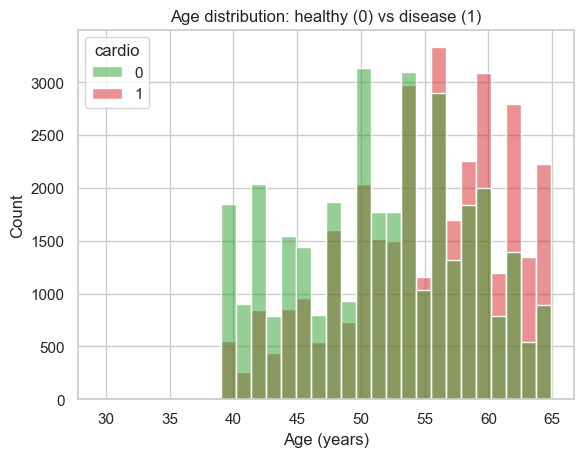

In [8]:
sns.histplot(data=df_clean, x="age_years", hue="cardio", bins=30, palette=["tab:green", "tab:red"])
plt.title("Age distribution: healthy (0) vs disease (1)")
plt.xlabel("Age (years)")
plt.show()

**How to read it:** the red bars (disease) dominate on the **right** (older ages), the green bars (healthy) on the **left**.
→ **Age is a useful feature.** Risk rises with age.

### 5b. Blood pressure: the strongest signal?

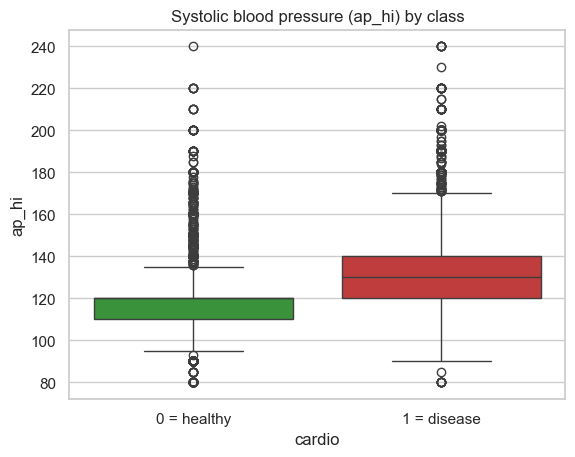

In [9]:
sns.boxplot(data=df_clean, x="cardio", y="ap_hi", hue="cardio", palette=["tab:green", "tab:red"], legend=False)
plt.xticks([0, 1], ["0 = healthy", "1 = disease"])
plt.title("Systolic blood pressure (ap_hi) by class")
plt.show()

**How to read a box plot:** the line in the middle of the box is the **median** (the middle value); the box covers the middle 50% of patients.

The disease group's box sits clearly **higher** (median ≈ 130 vs ≈ 120). → **Blood pressure is a strong feature.**

### 5c. Cholesterol and lifestyle: what % of each group has disease?

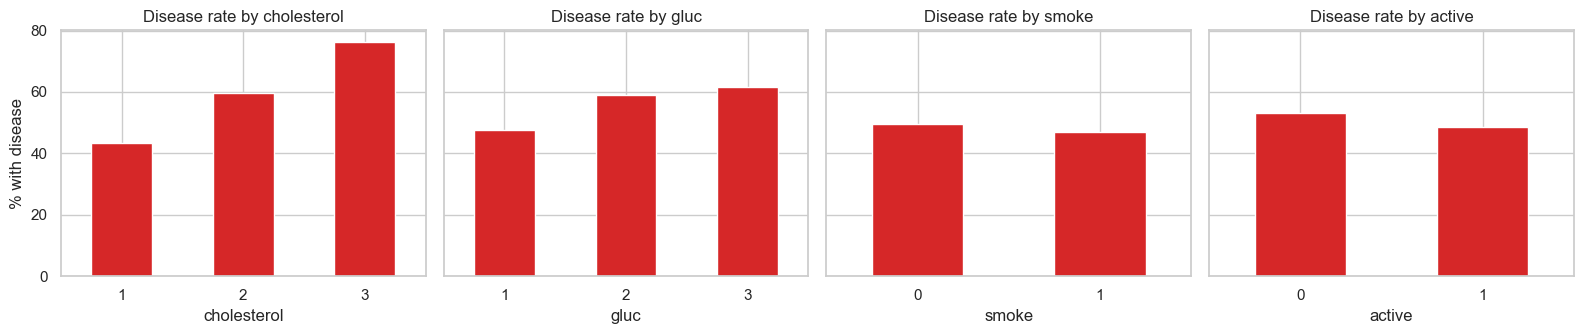

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, col in zip(axes, ["cholesterol", "gluc", "smoke", "active"]):
    # mean of a 0/1 column = the fraction of 1s = disease rate
    rate = df_clean.groupby(col)["cardio"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="tab:red")
    ax.set_title(f"Disease rate by {col}")
    ax.set_ylabel("% with disease")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

- **Cholesterol:** disease rate climbs from ≈ 44% (normal) to ≈ 77% (well above normal). Strong feature.
- **Glucose:** same direction, a bit weaker.
- **Smoke / active:** small differences. (Smoking looks surprisingly weak. It is self-reported, and 87% of smokers in this dataset are men — so its effect is mixed up with other factors. Real-world data can be messy!)

### 5d. Correlation heatmap: all features at once

**Correlation** is a number from −1 to +1:
- **+1** — when one goes up, the other goes up.
- **0** — no straight-line relationship.
- **−1** — when one goes up, the other goes down.

Focus on the **`cardio` row**: which features move with the target?

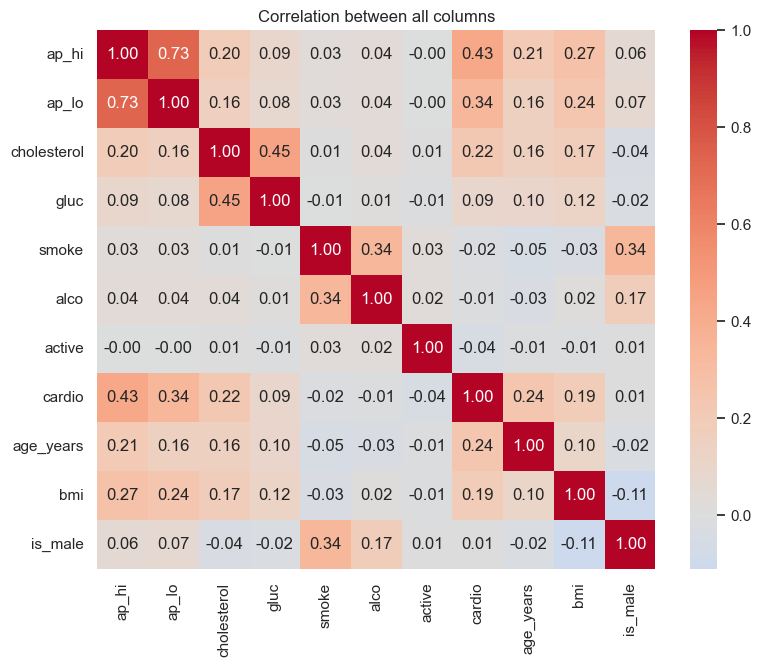

Correlation with cardio (sorted):
ap_hi          0.428
ap_lo          0.340
age_years      0.239
cholesterol    0.221
bmi            0.191
gluc           0.089
is_male        0.007
alco          -0.008
smoke         -0.016
active        -0.038
Name: cardio, dtype: float64


In [11]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between all columns")
plt.show()

print("Correlation with cardio (sorted):")
print(df_clean.corr()["cardio"].drop("cardio").sort_values(ascending=False).round(3))

**Top features:** `ap_hi`, `ap_lo`, `age_years`, `cholesterol`, `bmi`. These match medical knowledge — a good sign the data makes sense.

Note: correlation only catches *straight-line* relationships. A neural network can also learn curved / combined patterns
(Lecture 4: that's exactly why we add hidden layers).

## Step 6 — Split the data: train / validation / test

**Why split?** If we test the model on the same patients it learned from, it's like giving students the exam questions in advance —
the score means nothing. We need patients the model has **never seen** (Lecture 6).

```
  68,559 patients
  ├── TRAIN       70%  → the model learns from these
  ├── VALIDATION  15%  → we use these to make choices (e.g. decision threshold)
  └── TEST        15%  → touched ONCE at the very end = honest final score
```

**`stratify=y`** keeps the 50/50 healthy/disease ratio the same in every part.

First we separate **X** (features) from **y** (target).

In [12]:
X = df_clean.drop(columns=["cardio"])   # everything except the answer
y = df_clean["cardio"]                  # the answer

# 1st split: 70% train, 30% "temporary"
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

# 2nd split: cut the 30% in half → 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

print("Features used:", list(X.columns))
print(f"Train:      {len(X_train):>6} rows  ({y_train.mean():.1%} disease)")
print(f"Validation: {len(X_val):>6} rows  ({y_val.mean():.1%} disease)")
print(f"Test:       {len(X_test):>6} rows  ({y_test.mean():.1%} disease)")

Features used: ['ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'bmi', 'is_male']
Train:       47991 rows  (49.5% disease)
Validation:  10284 rows  (49.5% disease)
Test:        10284 rows  (49.5% disease)


## Step 7 — Scale the features

**Problem:** features live on very different scales:
`ap_hi` ≈ 120, `age_years` ≈ 53, `bmi` ≈ 27, `smoke` is 0 or 1.

A neural network multiplies each input by a weight. Big-number inputs dominate the sum and slow down learning;
an SVM measures distances, so the biggest-number feature would control everything.

**Solution — standardisation:** for every feature,
$$z = \frac{x - \text{mean}}{\text{standard deviation}}$$
After this, every feature has mean 0 and spread ≈ 1. A value of +2 means "2 standard deviations above average".

⚠ **Important rule:** compute the mean and standard deviation from the **training set only** (`fit`), then apply the same numbers
to validation and test (`transform`). If we used test data to compute them, information about the test set would *leak* into training.

In [13]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)   # learn mean/std from TRAIN, then scale train
X_val_s   = scaler.transform(X_val)         # reuse train's mean/std
X_test_s  = scaler.transform(X_test)        # reuse train's mean/std

# Show the effect on the first 3 training patients
print("BEFORE scaling:")
display(X_train.head(3).round(1))
print("AFTER scaling:")
display(pd.DataFrame(X_train_s[:3], columns=X.columns).round(2))

BEFORE scaling:


,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,bmi,is_male
15892,110,70,1,1,0,0,1,42.3,25.3,1
37630,120,80,1,1,0,0,1,58.5,23.4,0
27522,120,80,1,1,0,0,0,40.7,25.6,0


AFTER scaling:


,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,bmi,is_male
0,-1.0,-1.20,-0.54,-0.39,-0.31,-0.24,0.50,-1.63,-0.42,1.37
1,-0.4,-0.14,-0.54,-0.39,-0.31,-0.24,0.50,0.77,-0.77,-0.73
2,-0.4,-0.14,-0.54,-0.39,-0.31,-0.24,-2.02,-1.86,-0.37,-0.73


Example: a patient with `ap_hi = 150` becomes about **+1.4** (well above average), a patient with `ap_hi = 110` about **−1.0** (below average).

## Step 8 — Train our main model: an MLP neural network

This is the **Multi-Layer Perceptron** from Lectures 4–5.

```
  10 inputs          hidden layer 1      hidden layer 2       output
 (age, bp, bmi …)     (16 neurons)        (8 neurons)      P(disease)

   ap_hi  ○──┐        ○                   ○
   age    ○──┼──────▶ ○ ──────────────▶   ○  ──────────▶     ○  → 0.78
   bmi    ○──┤        ○                   ○
   ...    ○──┘        ...
```

**What `.fit()` does — exactly the backprop loop from class:**
1. **Forward pass:** push a batch of patients through the network → predicted probability.
2. **Error:** compare with the true answer (0 or 1).
3. **Backward pass:** backpropagation computes how much each weight contributed to the error.
4. **Update:** nudge every weight a little to reduce the error.
5. Repeat for many **epochs** (one epoch = one pass over all training data).

**Settings we choose (hyperparameters):**
- `hidden_layer_sizes=(16, 8)` — two hidden layers with 16 and 8 neurons. (Lecture 5: topology is chosen by experiment — try others later!)
- `activation="relu"` — the ReLU activation (Lecture 16: trains faster than sigmoid in hidden layers).
- `early_stopping=True` — keep 10% of the training data aside and **stop when its score stops improving** (Lecture 6: early stopping prevents overfitting).
- `max_iter=300` — at most 300 epochs.

In [14]:
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    early_stopping=True,
    max_iter=300,
    random_state=RANDOM_STATE,
)

mlp.fit(X_train_s, y_train)      # ← this is where the learning happens

print("Training finished after", mlp.n_iter_, "epochs")

Training finished after 37 epochs


### Watch it learn: the loss curve

**Loss** = how wrong the model is on the training data (lower = better). It should drop quickly, then flatten out.
The flat part means the model has learned what it can — early stopping then ends training.

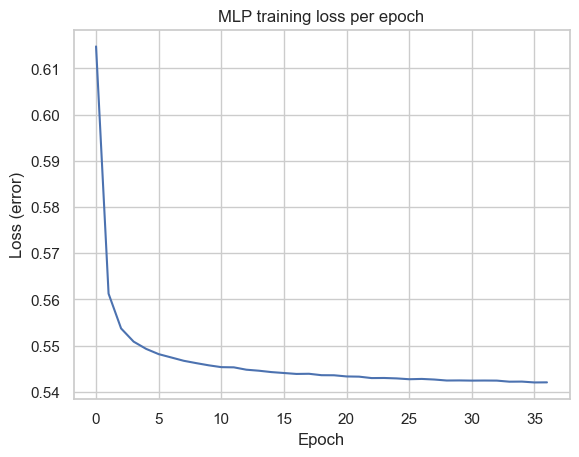

In [15]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss per epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss (error)")
plt.show()

## Step 9 — Evaluate the MLP on the validation set

The model gives each patient a **probability** of disease. We turn it into a yes/no decision with a **threshold** (default 0.5):

```
 probability ≥ 0.5  →  predict 1 (disease)
 probability < 0.5  →  predict 0 (healthy)
```

In [16]:
val_proba = mlp.predict_proba(X_val_s)[:, 1]   # column 1 = probability of class 1 (disease)
val_pred  = (val_proba >= 0.5).astype(int)

# Look at 8 example patients
examples = X_val.head(8).copy().round(1)
examples["P(disease)"] = val_proba[:8].round(2)
examples["prediction"] = val_pred[:8]
examples["TRUE answer"] = y_val.values[:8]
examples

,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,bmi,is_male,P(disease),prediction,TRUE answer
3565,140,90,1,1,0,0,0,39.9,31.7,1,0.88,1,1
14709,120,70,1,1,0,0,1,53.5,28.0,0,0.30,0,0
32932,120,80,1,1,0,0,0,48.3,23.5,1,0.28,0,0
53149,120,80,1,1,0,0,1,57.4,22.4,0,0.37,0,0
10938,180,100,1,1,0,0,1,59.7,24.2,0,0.87,1,0
21474,120,80,1,1,0,0,1,56.2,23.9,0,0.34,0,0
10413,115,70,1,1,0,0,1,51.7,27.2,0,0.24,0,0
31724,150,80,1,1,0,0,0,52.1,32.9,0,0.87,1,1


Compare the **prediction** and **TRUE answer** columns: most match, some don't. Now let's count *all* the matches and mistakes.

### The confusion matrix (Lecture 6)

```
                        predicted 0 (healthy)    predicted 1 (disease)
 actually 0 (healthy)   TN  ✔ correct            FP  ✘ false alarm
 actually 1 (disease)   FN  ✘ MISSED patient     TP  ✔ caught
```

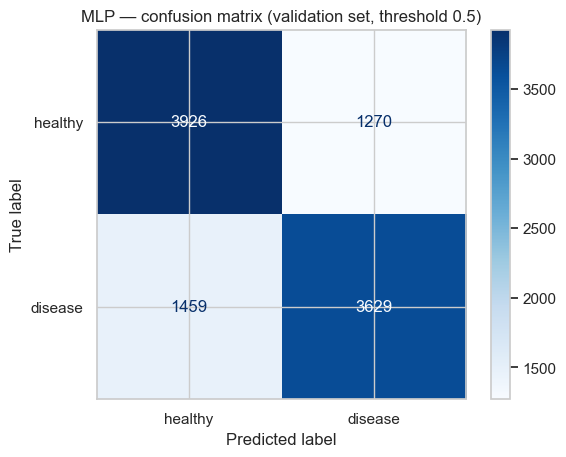

TN (healthy, correctly cleared): 3926
FP (healthy, false alarm):       1270
FN (sick, MISSED):               1459
TP (sick, correctly caught):     3629


In [17]:
cm = confusion_matrix(y_val, val_pred)
ConfusionMatrixDisplay(cm, display_labels=["healthy", "disease"]).plot(cmap="Blues", values_format="d")
plt.title("MLP — confusion matrix (validation set, threshold 0.5)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN (healthy, correctly cleared): {tn}")
print(f"FP (healthy, false alarm):       {fp}")
print(f"FN (sick, MISSED):               {fn}")
print(f"TP (sick, correctly caught):     {tp}")

### Turning the matrix into scores

| Metric | Formula | Plain-English question |
|---|---|---|
| **Accuracy** | (TP + TN) / all | How often is the model right overall? |
| **Precision** | TP / (TP + FP) | When it says "disease", how often is it right? |
| **Recall** | TP / (TP + FN) | Of all the truly sick people, how many did it catch? ← **most important in medicine** |
| **F1** | 2·P·R / (P + R) | One number balancing precision and recall |
| **ROC-AUC** | area under ROC curve | How well does it *rank* sick above healthy, across all thresholds? 0.5 = coin flip, 1.0 = perfect |

In [18]:
def evaluate(y_true, y_pred, y_proba):
    # Return the five scores for one model as a dictionary.
    return {
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall":    recall_score(y_true, y_pred),
        "f1":        f1_score(y_true, y_pred),
        "roc_auc":   roc_auc_score(y_true, y_proba),
    }

mlp_scores = evaluate(y_val, val_pred, val_proba)
for name, value in mlp_scores.items():
    print(f"{name:>9}: {value:.3f}")

 accuracy: 0.735
precision: 0.741
   recall: 0.713
       f1: 0.727
  roc_auc: 0.803


**Is ~73% accuracy good?** For this dataset, yes — published work on it typically reports **72–74%**.
The data has only basic checkup values (no ECG, no detailed tests), so there's a natural ceiling. Don't chase 95% here;
if you ever see it, suspect a bug or data leakage.

## Step 10 — Compare with other algorithms from the course

A single model's score means more when you compare it with alternatives. We train three more:

| Model | Lecture | Idea in one line |
|---|---|---|
| **SVM (RBF kernel)** | 8 | Find the widest-margin boundary; the kernel lets the boundary curve |
| **Random Forest** | 15 | Many decision trees on random samples of data/features, majority vote |
| **Naive Bayes** | 15 | Use probabilities, assuming features are independent given the class |

**Note on SVM speed:** SVM training time grows roughly with the *square* of the number of rows. On 48,000 rows it takes a long time,
so we train it on a random **10,000-row sample**. (This is a common, honest shortcut — just mention it in your report.)

In [19]:
# Random 10,000-row sample of the training set for the SVM
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(X_train_s), size=10_000, replace=False)

models = {
    "MLP (16, 8)":   mlp,   # already trained
    "SVM (RBF)":     SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1),
    "Naive Bayes":   GaussianNB(),
}

print("Training SVM (≈ 30–60 seconds)...")
models["SVM (RBF)"].fit(X_train_s[idx], y_train.values[idx])
print("Training Random Forest...")
models["Random Forest"].fit(X_train_s, y_train)
print("Training Naive Bayes...")
models["Naive Bayes"].fit(X_train_s, y_train)
print("Done ✔")

Training SVM (≈ 30–60 seconds)...


Training Random Forest...


Training Naive Bayes...
Done ✔


In [20]:
results = {}
for name, model in models.items():
    proba = model.predict_proba(X_val_s)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results[name] = evaluate(y_val, pred, proba)

results_table = pd.DataFrame(results).T.round(3)
results_table.sort_values("roc_auc", ascending=False)

,accuracy,precision,recall,f1,roc_auc
Random Forest,0.737,0.764,0.677,0.718,0.804
"MLP (16, 8)",0.735,0.741,0.713,0.727,0.803
SVM (RBF),0.737,0.748,0.705,0.726,0.794
Naive Bayes,0.713,0.763,0.609,0.678,0.781


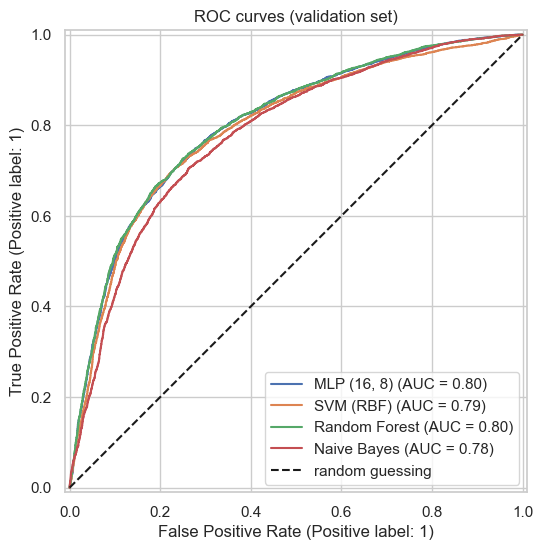

In [21]:
# ROC curves: every point is one possible threshold. Closer to the top-left corner = better.
fig, ax = plt.subplots(figsize=(6, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_val_s, y_val, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="random guessing")
ax.set_title("ROC curves (validation set)")
ax.legend()
plt.show()

**What you should see:**
- **MLP, SVM and Random Forest perform very similarly** (≈ 72–74% accuracy, ROC-AUC ≈ 0.79–0.80).
- **Naive Bayes is a bit weaker** — its "features are independent" assumption is wrong here (e.g. `ap_hi` and `ap_lo` are strongly related).

When several very different algorithms hit the same ceiling, that tells you the **limit is in the data, not the algorithm**.
That's a valid and interesting finding to discuss in your report.

### Which features does the Random Forest rely on?
Random Forests can report **feature importance**: how much each feature helped the trees make good splits.

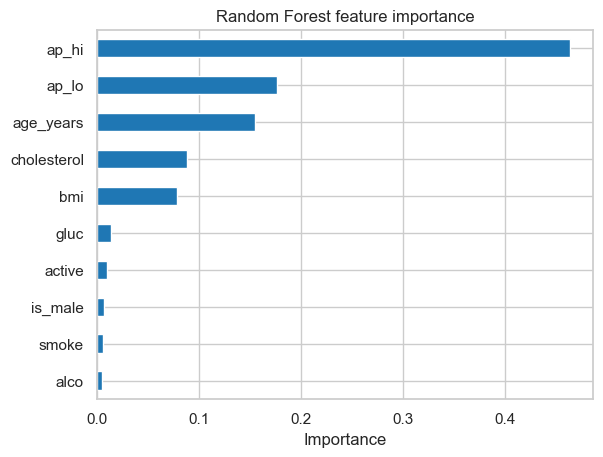

In [22]:
importance = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", color="tab:blue")
plt.title("Random Forest feature importance")
plt.xlabel("Importance")
plt.show()

Blood pressure (`ap_hi`, `ap_lo`), `age_years`, `cholesterol` and `bmi` lead — the **same features** our EDA charts pointed to in Step 5.
When EDA and the model agree, you can trust the result more.

## Step 11 — Choose a threshold that catches more sick patients

So far we used threshold **0.5**. But in medicine the two mistakes are not equally bad:

- **False alarm (FP):** a healthy person gets an extra check-up → inconvenient.
- **Missed patient (FN):** a sick person is sent home → dangerous.

**Lowering the threshold** makes the model say "disease" more often:
recall goes **up** (fewer missed patients), precision goes **down** (more false alarms).
Let's see the trade-off for the MLP on the validation set.

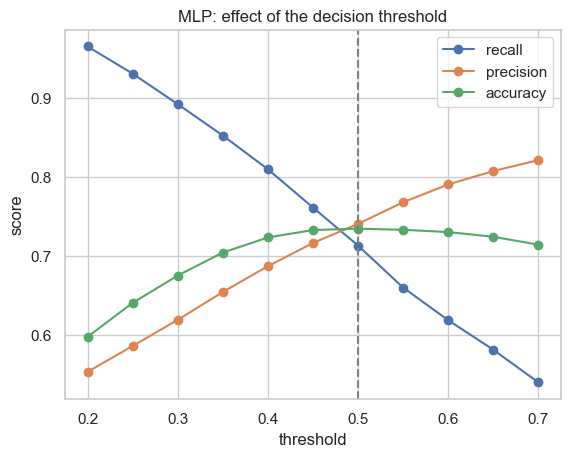

,threshold,recall,precision,accuracy
0,0.20,0.965,0.554,0.598
1,0.25,0.931,0.586,0.641
2,0.30,0.892,0.619,0.675
3,0.35,0.852,0.655,0.704
4,0.40,0.810,0.687,0.724
5,0.45,0.761,0.717,0.733
6,0.50,0.713,0.741,0.735
7,0.55,0.660,0.768,0.733
8,0.60,0.619,0.791,0.730
9,0.65,0.582,0.808,0.724


In [23]:
thresholds = np.arange(0.20, 0.71, 0.05)
rows = []
for t in thresholds:
    pred_t = (val_proba >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "recall":    recall_score(y_val, pred_t),
        "precision": precision_score(y_val, pred_t),
        "accuracy":  accuracy_score(y_val, pred_t),
    })
trade_off = pd.DataFrame(rows)

trade_off.plot(x="threshold", y=["recall", "precision", "accuracy"], marker="o")
plt.axvline(0.5, color="grey", linestyle="--")
plt.title("MLP: effect of the decision threshold")
plt.ylabel("score")
plt.show()

trade_off.round(3)

**Our choice:** we want **recall ≥ 0.80** (catch at least 80% of sick patients) while keeping as much precision as possible.
The code below picks the *highest* threshold that still reaches that recall.

In [24]:
TARGET_RECALL = 0.80
ok = trade_off[trade_off["recall"] >= TARGET_RECALL]
chosen_threshold = ok["threshold"].max()
print("Chosen threshold:", chosen_threshold)

Chosen threshold: 0.4


### Final, honest score on the TEST set

We made all our choices (model settings, threshold) using **train + validation**. Now — **once** — we check the test set,
which played no part in any decision. This is the number you report.

--- MLP on TEST set, threshold = 0.5 ---
 accuracy: 0.733
precision: 0.741
   recall: 0.708
       f1: 0.724
  roc_auc: 0.794

--- MLP on TEST set, threshold = 0.4 ---
 accuracy: 0.712
precision: 0.677
   recall: 0.797
       f1: 0.732
  roc_auc: 0.794



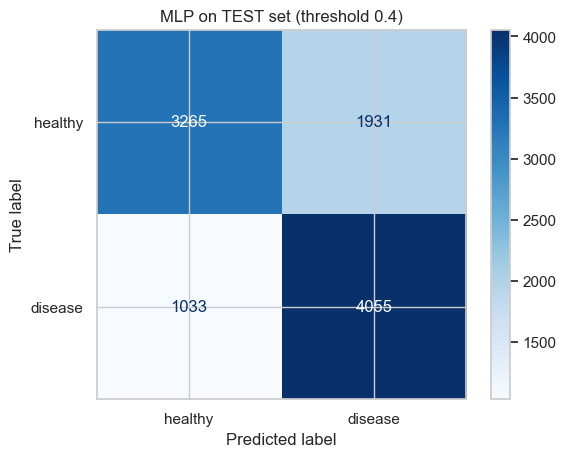

In [25]:
test_proba = mlp.predict_proba(X_test_s)[:, 1]

for t in [0.5, chosen_threshold]:
    test_pred = (test_proba >= t).astype(int)
    print(f"--- MLP on TEST set, threshold = {t} ---")
    for name, value in evaluate(y_test, test_pred, test_proba).items():
        print(f"{name:>9}: {value:.3f}")
    print()

test_pred = (test_proba >= chosen_threshold).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred),
                       display_labels=["healthy", "disease"]).plot(cmap="Blues", values_format="d")
plt.title(f"MLP on TEST set (threshold {chosen_threshold})")
plt.show()

Compare the two blocks: with the lower threshold, **recall rises** (fewer missed patients) and precision drops a bit.
Recall on the test set lands close to — maybe slightly under — the 80% we targeted on validation. That's normal: a threshold chosen on one set of patients never transfers *exactly* to another.
That is a deliberate, explainable design decision — exactly the kind of thing to discuss in your presentation.

## Step 12 — Use the model on a new patient (the start of our agent)

This is what the final system will do. A function takes a patient's raw checkup values and returns the risk.

Notice the function repeats the **same preparation steps** as training (age in years, BMI, is_male, scaling with the *training* scaler).
A new patient must go through exactly the same pipeline as the training data.

In [26]:
def predict_risk(age_years, is_male, height_cm, weight_kg, ap_hi, ap_lo,
                 cholesterol, gluc, smoke, alco, active):
    # Return the MLP's probability (0–1) that this patient has cardiovascular disease.
    patient = pd.DataFrame([{
        "ap_hi": ap_hi, "ap_lo": ap_lo, "cholesterol": cholesterol, "gluc": gluc,
        "smoke": smoke, "alco": alco, "active": active,
        "age_years": age_years,
        "bmi": weight_kg / (height_cm / 100) ** 2,
        "is_male": is_male,
    }])[X.columns]                               # same column order as training
    patient_s = scaler.transform(patient)        # same scaling as training
    return mlp.predict_proba(patient_s)[0, 1]


patient = dict(age_years=50, is_male=1, height_cm=175, weight_kg=90, ap_hi=135, ap_lo=85,
               cholesterol=2, gluc=1, smoke=1, alco=0, active=0)

risk = predict_risk(**patient)
label = "HIGH RISK ⚠" if risk >= chosen_threshold else "lower risk"
print(f"Predicted probability of disease: {risk:.0%}  →  {label}")

Predicted probability of disease: 88%  →  HIGH RISK ⚠


### "What-if": which lifestyle change helps most?

The agent idea: change only things the patient **can** change, re-run the model, and compare.
This uses nothing new — just repeated predictions.

Current situation                87.7 %
Quits smoking                    82.6 %
Becomes physically active        82.0 %
Loses 10 kg                      86.7 %
Blood pressure down to 120/80    61.2 %
Cholesterol back to normal       72.9 %
ALL of the above                 28.0 %
dtype: object


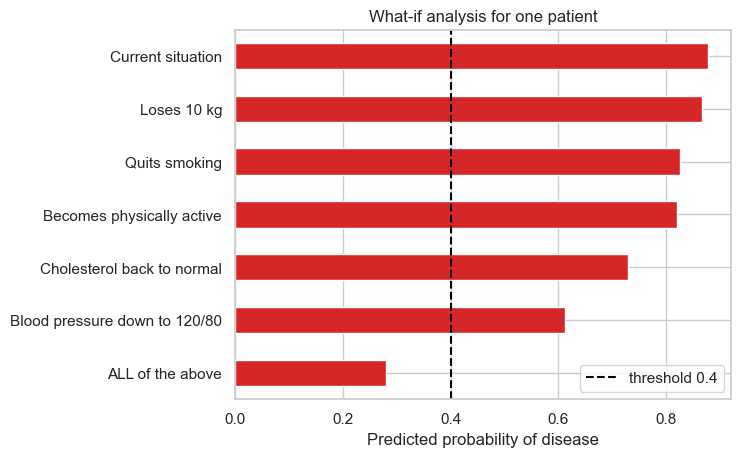

In [27]:
scenarios = {
    "Current situation":            {},
    "Quits smoking":                {"smoke": 0},
    "Becomes physically active":    {"active": 1},
    "Loses 10 kg":                  {"weight_kg": patient["weight_kg"] - 10},
    "Blood pressure down to 120/80": {"ap_hi": 120, "ap_lo": 80},
    "Cholesterol back to normal":   {"cholesterol": 1},
    "ALL of the above":             {"smoke": 0, "active": 1, "weight_kg": patient["weight_kg"] - 10,
                                     "ap_hi": 120, "ap_lo": 80, "cholesterol": 1},
}

what_if = pd.Series({name: predict_risk(**{**patient, **change}) for name, change in scenarios.items()})
print((what_if * 100).round(1).astype(str) + " %")

what_if.sort_values().plot(kind="barh", color="tab:red")
plt.axvline(chosen_threshold, color="black", linestyle="--", label=f"threshold {chosen_threshold}")
plt.xlabel("Predicted probability of disease")
plt.title("What-if analysis for one patient")
plt.legend()
plt.show()

For this patient the model says **blood pressure** is by far the biggest lever, then **cholesterol** — consistent with EDA and feature importance.

⚠ **Check before you trust:** an MLP is not forced to be sensible for every patient. Try other patients and you may find a change that moves the risk the "wrong" way (e.g. lower cholesterol → slightly higher risk). That is a model quirk, not medicine — a good thing to test and discuss in your project.

⚠ **Honest caveat (put this in your report):** the model learned *associations* in the data, not *causes*.
"If smoke were 0, the model predicts lower risk" is not the same as "quitting will lower this person's risk by X%".
The agent is a **decision-support** tool, not a doctor.

## Summary — what you just did

```
 raw CSV (70,000) ─▶ clean (68,559) ─▶ new features ─▶ split 70/15/15 ─▶ scale
       ─▶ train MLP (backprop) ─▶ confusion matrix & metrics ─▶ compare SVM / RF / NB
       ─▶ choose threshold for recall ≥ 80% ─▶ final TEST score ─▶ predict + what-if
```

**Key lessons**
1. Always **look at the data** first — `describe()` revealed impossible blood pressures.
2. **Never evaluate on training data.** Validation for choices, test once at the end.
3. **Fit the scaler on training data only** to avoid leakage.
4. Different algorithms reached a similar ceiling (~73%) → the limit is the **information in the data**.
5. In medicine, **recall** matters; the threshold is a design choice you can justify.

### Next notebooks (where the project's novelty comes in)
- **Part 2 — Genetic Algorithm (Lectures 12–13):** let a GA search for the best feature subset and MLP size, with validation recall as fitness.
- **Part 3 — Patient profiles (Lectures 9–10, 7):** k-means / SOM clustering to find risk groups; PCA/LDA to visualise them.
- **Part 4 — The agent (Lecture 11):** wrap `predict_risk` + what-if + profile into a "Heart Risk Advisor" and describe it with PEAS.

### Try it yourself (good practice)
- Change `hidden_layer_sizes` to `(32,)`, `(32, 16)` or `(8,)` and re-run Steps 8–9. Does the score change?
- Change `TARGET_RECALL` to 0.85 or 0.90. What happens to precision?
- Try your own numbers in `patient` in Step 12.